# Traffic-Sensor Graph Construction

In [8]:
!git clone https://github.com/mansiguptacs/CMPE_258_TrafficForecastingUsing_GraphNN.git

Cloning into 'CMPE_258_TrafficForecastingUsing_GraphNN'...
remote: Enumerating objects: 70, done.
remote: Counting objects: 100% (70/70), done.
remote: Compressing objects: 100% (49/49), done.
remote: Total 70 (delta 20), reused 57 (delta 15), pack-reused 0 (from 0)
Receiving objects: 100% (70/70), 31.40 KiB | 31.40 MiB/s, done.
Resolving deltas: 100% (20/20), done.


In [9]:
%cd CMPE_258_TrafficForecastingUsing_GraphNN

/content/CMPE_258_TrafficForecastingUsing_GraphNN/CMPE_258_TrafficForecastingUsing_GraphNN


In [10]:
!pip install -r requirements.txt -q

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [11]:
!find "/content/drive/MyDrive" -maxdepth 5 -type d | grep -E "processed|project_dataset|Traffic|258"

/content/drive/MyDrive/cmp258-03_fa26_assignment_2
/content/drive/MyDrive/cmp258-03_fa26_assignment_2/utils
/content/drive/MyDrive/cmp258-03_fa26_assignment_2/models
/content/drive/MyDrive/CMPE258_TrafficForecastingUsing_GraphNN
/content/drive/MyDrive/CMPE258_TrafficForecastingUsing_GraphNN/data
/content/drive/MyDrive/CMPE258_TrafficForecastingUsing_GraphNN/data/raw
/content/drive/MyDrive/CMPE258_TrafficForecastingUsing_GraphNN/data/processed


In [7]:
!pwd

/content/CMPE_258_TrafficForecastingUsing_GraphNN


In [15]:
!mkdir -p data/raw data/processed

In [16]:
!cp "/content/drive/MyDrive/CMPE258_TrafficForecastingUsing_GraphNN/data/raw/adj_mx.pkl" data/raw/

In [17]:
!cp "/content/drive/MyDrive/CMPE258_TrafficForecastingUsing_GraphNN/data/processed/"* data/processed/

In [18]:
!ls -lh data/raw data/processed


data/processed:
total 32M
-rw------- 1 root root  898 Oct 19 00:22 meta.json
-rw------- 1 root root  32M Oct 19 00:22 metr_la_processed.npz
-rw------- 1 root root 7.9K Oct 19 00:22 scalers.json

data/raw:
total 668K
-rw------- 1 root root 665K Oct 19 00:21 adj_mx.pkl


In [19]:
import numpy as np

data = np.load("data/processed/metr_la_processed.npz")

print("Files inside dataset:", data.files)

for name in data.files:
    print(name, data[name].shape, data[name].dtype)

Files inside dataset: ['speeds', 'inputs', 'observed', 'timestamps', 'sensor_ids', 'adj_distance']
speeds (34272, 207) float32
inputs (34272, 207) float32
observed (34272, 207) bool
timestamps (34272,) int64
sensor_ids (207,) <U6
adj_distance (207, 207) float32


In [20]:
!wget -O data/raw/distances_la_2012.csv https://raw.githubusercontent.com/liyaguang/DCRNN/master/data/sensor_graph/distances_la_2012.csv

--2026-10-19 00:25:14--  https://raw.githubusercontent.com/liyaguang/DCRNN/master/data/sensor_graph/distances_la_2012.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.110.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 6393348 (6.1M) [text/plain]
Saving to: ‘data/raw/distances_la_2012.csv’

data/raw/distances_ 100%[===================>]   6.10M  --.-KB/s    in 0.03s   

2026-10-19 00:25:14 (237 MB/s) - ‘data/raw/distances_la_2012.csv’ saved [6393348/6393348]



In [21]:
!wget -O data/raw/graph_sensor_ids.txt https://raw.githubusercontent.com/liyaguang/DCRNN/master/data/sensor_graph/graph_sensor_ids.txt

--2026-10-19 00:25:34--  https://raw.githubusercontent.com/liyaguang/DCRNN/master/data/sensor_graph/graph_sensor_ids.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.108.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1448 (1.4K) [text/plain]
Saving to: ‘data/raw/graph_sensor_ids.txt’

data/raw/graph_sens 100%[===================>]   1.41K  --.-KB/s    in 0s      

2026-10-19 00:25:34 (18.4 MB/s) - ‘data/raw/graph_sensor_ids.txt’ saved [1448/1448]



In [22]:
!head -5 data/raw/distances_la_2012.csv
!head -10 data/raw/graph_sensor_ids.txt


from,to,cost
1201054,1201054,0.0
1201054,1201066,2610.9
1201054,1201076,2822.7
1201054,1201087,2911.5
773869,767541,767542,717447,717446,717445,773062,767620,737529,717816,765604,767471,716339,773906,765273,716331,771667,716337,769953,769402,769403,769819,769405,716941,717578,716960,717804,767572,767573,773012,773013,764424,769388,716328,717819,769941,760987,718204,718045,769418,768066,772140,773927,760024,774012,774011,767609,769359,760650,716956,769831,761604,717495,716554,773953,767470,716955,764949,773954,767366,769444,773939,774067,769443,767750,767751,767610,773880,764766,717497,717490,717491,717492,717493,765176,717498,717499,765171,718064,718066,765164,769431,769430,717610,767053,767621,772596,772597,767350,767351,716571,773023,767585,773024,717483,718379,717481,717480,717486,764120,772151,718371,717489,717488,717818,718076,718072,767455,767454,761599,717099,773916,716968,769467,717576,717573,717572,717571,717570,764760,718089,769847,717608,767523,716942,718090,769867,717472,71

## 1. Distance-Based Traffic-Sensor Graph

In this section, we construct a traffic-sensor graph using the physical road
distances between sensors. The distance values are converted into edge weights
using a Gaussian kernel, and weak connections are removed using a threshold.

In [36]:

import numpy as np
import pandas as pd
import json

with open("data/raw/graph_sensor_ids.txt") as f:
    sensor_ids = f.read().strip().split(",")

sensor_ids = [str(sensor_id) for sensor_id in sensor_ids]

sensor_to_index = {
    sensor_id: index
    for index, sensor_id in enumerate(sensor_ids)
}

print("Number of sensors:", len(sensor_ids))

Number of sensors: 207


In [37]:
distance_df = pd.read_csv(
    "data/raw/distances_la_2012.csv"
)

print(distance_df.head())
print("Number of distance records:", len(distance_df))

      from       to    cost
0  1201054  1201054     0.0
1  1201054  1201066  2610.9
2  1201054  1201076  2822.7
3  1201054  1201087  2911.5
4  1201054  1201100  7160.1
Number of distance records: 295374


In [38]:
sigma = distance_df["cost"].std()
threshold = 0.1

num_sensors = len(sensor_ids)

adj_distance = np.zeros(
    (num_sensors, num_sensors),
    dtype=np.float32
)

print("Sigma:", sigma)
print("Threshold:", threshold)
print("Adjacency matrix shape:", adj_distance.shape)

Sigma: 2659.8865868691605
Threshold: 0.1
Adjacency matrix shape: (207, 207)


In [39]:
for row in distance_df.itertuples(index=False):
    source_sensor = str(row[0])
    target_sensor = str(row[1])
    distance = float(row[2])

    if (
        source_sensor in sensor_to_index
        and target_sensor in sensor_to_index
    ):
        source_index = sensor_to_index[source_sensor]
        target_index = sensor_to_index[target_sensor]

        weight = np.exp(-((distance / sigma) ** 2))

        if weight >= threshold:
            adj_distance[source_index, target_index] = weight

print("Distance weights assigned.")

Distance weights assigned.


In [40]:
np.fill_diagonal(adj_distance, 0)

nonzero_edges = adj_distance > 0

print("Graph shape:", adj_distance.shape)
print("Directed connections:", nonzero_edges.sum())
print("Minimum edge weight:", adj_distance[nonzero_edges].min())
print("Maximum edge weight:", adj_distance.max())

Graph shape: (207, 207)
Directed connections: 1596
Minimum edge weight: 0.10005524
Maximum edge weight: 0.9998414


In [41]:
np.save(
    "data/raw/adj_distance.npy",
    adj_distance
)

print("Distance graph saved successfully.")

Distance graph saved successfully.


In [42]:
connection_mask = (
    (adj_distance > 0) |
    (adj_distance.T > 0)
)

degree = connection_mask.sum(axis=1)
isolated_indices = np.where(degree == 0)[0]

print("Average total degree:", degree.mean())
print("Maximum total degree:", degree.max())
print("Number of isolated sensors:", len(isolated_indices))
print(
    "Isolated sensor IDs:",
    [sensor_ids[i] for i in isolated_indices]
)

Average total degree: 13.31400966183575
Maximum total degree: 25
Number of isolated sensors: 1
Isolated sensor IDs: ['717804']


In [43]:
distance_metadata = {
    "num_sensors": int(num_sensors),
    "directed_connections": int(nonzero_edges.sum()),
    "average_total_degree": float(degree.mean()),
    "maximum_total_degree": int(degree.max()),
    "isolated_sensor_ids": [
        sensor_ids[i] for i in isolated_indices
    ],
    "kernel": "exp(-(distance / sigma)^2)",
    "sigma": float(sigma),
    "threshold": float(threshold),
    "source": "distances_la_2012.csv"
}

with open(
    "data/raw/adj_distance_metadata.json",
    "w"
) as f:
    json.dump(distance_metadata, f, indent=2)

print("Distance graph metadata saved.")
print(distance_metadata)

Distance graph metadata saved.
{'num_sensors': 207, 'directed_connections': 1596, 'average_total_degree': 13.31400966183575, 'maximum_total_degree': 25, 'isolated_sensor_ids': ['717804'], 'kernel': 'exp(-(distance / sigma)^2)', 'sigma': 2659.8865868691605, 'threshold': 0.1, 'source': 'distances_la_2012.csv'}


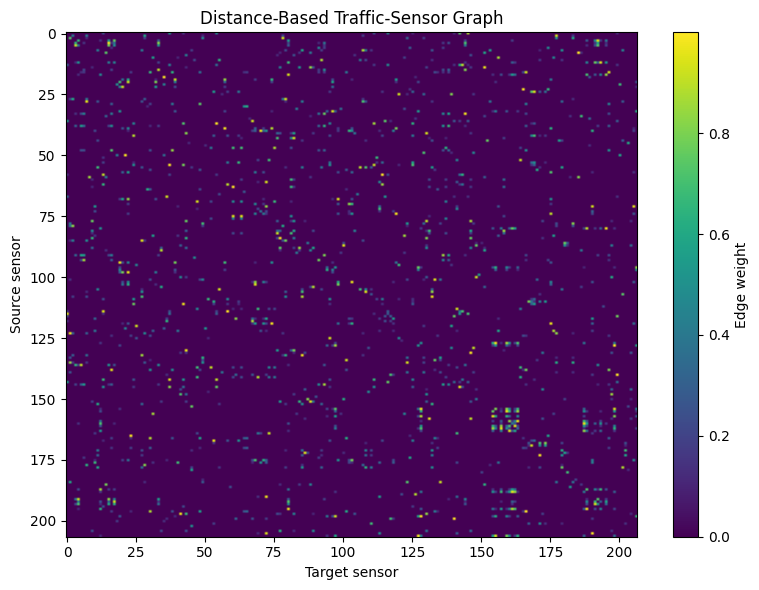

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.imshow(
    adj_distance,
    cmap="viridis",
    aspect="auto"
)

plt.colorbar(label="Edge weight")
plt.title("Distance-Based Traffic-Sensor Graph")
plt.xlabel("Target sensor")
plt.ylabel("Source sensor")

plt.tight_layout()
plt.savefig(
    "data/raw/distance_graph_heatmap.png",
    dpi=200
)

plt.show()

In [45]:
!cp data/raw/adj_distance.npy \
"/content/drive/MyDrive/CMPE258_TrafficForecastingUsing_GraphNN/data/raw/"

!cp data/raw/adj_distance_metadata.json \
"/content/drive/MyDrive/CMPE258_TrafficForecastingUsing_GraphNN/data/raw/"

!cp data/raw/distance_graph_heatmap.png \
"/content/drive/MyDrive/CMPE258_TrafficForecastingUsing_GraphNN/data/raw/"

In [47]:
!git switch -c megha-work

Switched to a new branch 'megha-work'


In [48]:
!git branch --show-current

megha-work


## 2. Correlation-Based Traffic-Sensor Graph

In this section, we construct a second traffic-sensor graph using the
correlation between sensor speed measurements. Only the training portion
of the data is used to avoid data leakage.

In [49]:
speeds = data["speeds"]
observed = data["observed"]

print("Speed data shape:", speeds.shape)
print("Observation mask shape:", observed.shape)

Speed data shape: (34272, 207)
Observation mask shape: (34272, 207)


In [50]:
train_end = int(len(speeds) * 0.70)

train_speeds = speeds[:train_end]
train_observed = observed[:train_end]

print("Training rows:", train_speeds.shape[0])
print("Training data shape:", train_speeds.shape)

Training rows: 23990
Training data shape: (23990, 207)


In [51]:
train_df = pd.DataFrame(train_speeds)

train_df = train_df.mask(
    ~train_observed
)

print("Training DataFrame shape:", train_df.shape)
print("Missing values:", train_df.isna().sum().sum())

Training DataFrame shape: (23990, 207)
Missing values: 354180


In [52]:
correlation = train_df.corr()

correlation = correlation.abs().fillna(0)

np.fill_diagonal(
    correlation.values,
    0
)

print("Correlation matrix shape:", correlation.shape)
print(correlation.head())

Correlation matrix shape: (207, 207)
        0         1         2         3         4         5         6    \
0  0.000000  0.330766  0.053842  0.323314  0.177767  0.245928  0.418767   
1  0.330766  0.000000  0.066754  0.193460  0.059692  0.127210  0.213813   
2  0.053842  0.066754  0.000000  0.113367  0.169225  0.100027  0.121540   
3  0.323314  0.193460  0.113367  0.000000  0.500970  0.703801  0.428698   
4  0.177767  0.059692  0.169225  0.500970  0.000000  0.306407  0.500296   

        7         8         9    ...       197       198       199       200  \
0  0.273400  0.082229  0.131429  ...  0.400847  0.640029  0.564769  0.011940   
1  0.440419  0.094516  0.009277  ...  0.198993  0.340299  0.315155  0.105819   
2  0.106796  0.383598  0.597624  ...  0.077511  0.065874  0.014271  0.060645   
3  0.297908  0.037787  0.136729  ...  0.389553  0.458514  0.383843  0.240408   
4  0.274786  0.073137  0.283216  ...  0.387997  0.305877  0.237821  0.394601   

        201       202       203

In [54]:
top_k = 10

adj_correlation = np.zeros(
    correlation.shape,
    dtype=np.float32
)

for sensor_index in range(correlation.shape[0]):
    strongest_sensors = np.argsort(
        correlation.iloc[sensor_index].values
    )[-top_k:]

    adj_correlation[
        sensor_index,
        strongest_sensors
    ] = correlation.iloc[
        sensor_index,
        strongest_sensors
    ].values

print("Top-k correlation graph created.")
print("Top-k value:", top_k)

Top-k correlation graph created.
Top-k value: 10


In [55]:
adj_correlation = np.maximum(
    adj_correlation,
    adj_correlation.T
)

np.fill_diagonal(
    adj_correlation,
    0
)

print("Symmetric correlation graph created.")
print(
    "Is symmetric:",
    np.allclose(adj_correlation, adj_correlation.T)
)

Symmetric correlation graph created.
Is symmetric: True


In [56]:
correlation_edges = adj_correlation > 0
correlation_degree = correlation_edges.sum(axis=1)

print("Graph shape:", adj_correlation.shape)
print("Number of connections:", correlation_edges.sum())
print("Minimum degree:", correlation_degree.min())
print("Average degree:", correlation_degree.mean())
print("Maximum degree:", correlation_degree.max())
print("Minimum edge weight:", adj_correlation[correlation_edges].min())
print("Maximum edge weight:", adj_correlation.max())

Graph shape: (207, 207)
Number of connections: 2926
Minimum degree: 10
Average degree: 14.135265700483092
Maximum degree: 39
Minimum edge weight: 0.12774996
Maximum edge weight: 0.97939706


In [57]:
np.save(
    "data/raw/adj_correlation.npy",
    adj_correlation
)

correlation_metadata = {
    "num_sensors": int(adj_correlation.shape[0]),
    "training_rows": int(train_end),
    "connections": int(correlation_edges.sum()),
    "top_k": int(top_k),
    "correlation_type": "absolute Pearson correlation",
    "missing_values_excluded": True,
    "symmetric": bool(
        np.allclose(adj_correlation, adj_correlation.T)
    ),
    "minimum_degree": int(correlation_degree.min()),
    "average_degree": float(correlation_degree.mean()),
    "maximum_degree": int(correlation_degree.max())
}

with open(
    "data/raw/adj_correlation_metadata.json",
    "w"
) as f:
    json.dump(correlation_metadata, f, indent=2)

print("Correlation graph and metadata saved.")

Correlation graph and metadata saved.


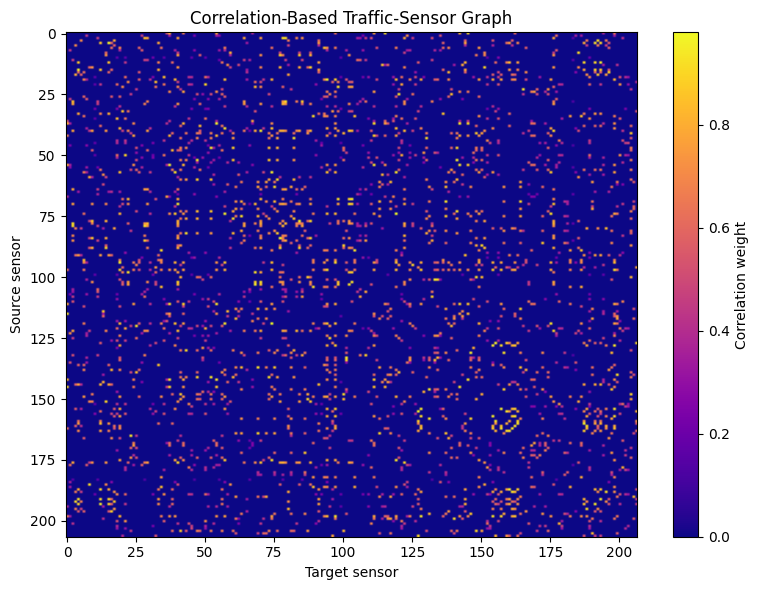

In [58]:
plt.figure(figsize=(8, 6))

plt.imshow(
    adj_correlation,
    cmap="plasma",
    aspect="auto"
)

plt.colorbar(label="Correlation weight")
plt.title("Correlation-Based Traffic-Sensor Graph")
plt.xlabel("Target sensor")
plt.ylabel("Source sensor")

plt.tight_layout()
plt.savefig(
    "data/raw/correlation_graph_heatmap.png",
    dpi=200
)

plt.show()

In [59]:
!cp data/raw/adj_correlation.npy \
"/content/drive/MyDrive/CMPE258_TrafficForecastingUsing_GraphNN/data/raw/"

!cp data/raw/adj_correlation_metadata.json \
"/content/drive/MyDrive/CMPE258_TrafficForecastingUsing_GraphNN/data/raw/"

!cp data/raw/correlation_graph_heatmap.png \
"/content/drive/MyDrive/CMPE258_TrafficForecastingUsing_GraphNN/data/raw/"

In [60]:
distance_connections = (
    (adj_distance > 0) |
    (adj_distance.T > 0)
)

correlation_connections = (
    adj_correlation > 0
)

np.fill_diagonal(distance_connections, False)
np.fill_diagonal(correlation_connections, False)

print("Distance graph connections:", distance_connections.sum())
print("Correlation graph connections:", correlation_connections.sum())

Distance graph connections: 2756
Correlation graph connections: 2926


In [61]:
upper_triangle = np.triu(
    np.ones(distance_connections.shape, dtype=bool),
    k=1
)

distance_edges = distance_connections & upper_triangle
correlation_edges = correlation_connections & upper_triangle

shared_edges = distance_edges & correlation_edges
union_edges = distance_edges | correlation_edges

print("Unique distance edges:", distance_edges.sum())
print("Unique correlation edges:", correlation_edges.sum())
print("Shared edges:", shared_edges.sum())
print("Union edges:", union_edges.sum())

overlap_percentage = (
    shared_edges.sum() / union_edges.sum()
) * 100

print("Jaccard edge overlap:", round(overlap_percentage, 2), "%")

Unique distance edges: 1378
Unique correlation edges: 1463
Shared edges: 624
Union edges: 2217
Jaccard edge overlap: 28.15 %


In [62]:
graph_comparison = {
    "unique_distance_edges": int(distance_edges.sum()),
    "unique_correlation_edges": int(correlation_edges.sum()),
    "shared_edges": int(shared_edges.sum()),
    "union_edges": int(union_edges.sum()),
    "jaccard_overlap_percent": round(
        float(overlap_percentage),
        2
    ),
    "distance_edges_shared_percent": round(
        float(shared_edges.sum() / distance_edges.sum() * 100),
        2
    ),
    "correlation_edges_shared_percent": round(
        float(shared_edges.sum() / correlation_edges.sum() * 100),
        2
    )
}

with open(
    "data/raw/graph_comparison_metadata.json",
    "w"
) as f:
    json.dump(graph_comparison, f, indent=2)

print(graph_comparison)

{'unique_distance_edges': 1378, 'unique_correlation_edges': 1463, 'shared_edges': 624, 'union_edges': 2217, 'jaccard_overlap_percent': 28.15, 'distance_edges_shared_percent': 45.28, 'correlation_edges_shared_percent': 42.65}


In [63]:
!cp data/raw/graph_comparison_metadata.json \
"/content/drive/MyDrive/CMPE258_TrafficForecastingUsing_GraphNN/data/raw/"